# Simple Linear Regression

Fit and interpret a one-predictor regression of salary on training hours.

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")

from pathlib import Path


def find_repo_root(start=Path.cwd()):
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path
    raise RuntimeError("Could not find repository root")


ROOT = find_repo_root()
DATA = ROOT / "data"

In [9]:
df = pd.read_csv(DATA / "career_outcomes.csv")
df.head()

,experience_years,education_years,training_hours,sector,remote,ai_tool_use,salary_k_eur,promoted
0,1.2,12,38.2,technology,0,4.8,60.2,0
1,5.1,16,20.7,technology,1,4.0,66.5,1
2,8.5,14,60.5,retail,0,8.2,76.5,1
3,9.7,16,38.7,finance,0,0.7,84.7,0
4,2.5,16,60.7,public,0,4.7,67.6,0


## Analytic question

How much does salary tend to change with additional training hours? State the outcome, predictor, expected direction, and one plausible omitted variable.

The outcome is the annual salary in thousand EUR and the predictor is the number of training hours. We expect a positive slope, workers who train more should be more productive and get paid more. One plausible omitted variable is AI tool use: in the data it moves together with training hours (correlation 0.62) and with salary (0.40), so a simple regression on training hours alone will pick up part of that as well.

[Text(0.5, 1.0, 'Salary and training hours'),
 Text(0.5, 0, 'Training hours'),
 Text(0, 0.5, 'Salary, thousand EUR')]

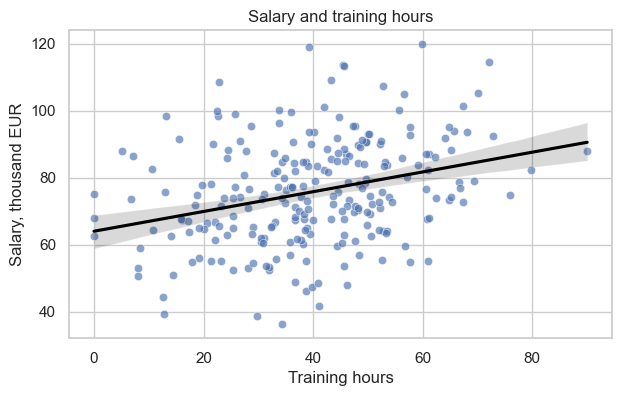

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df, x="training_hours", y="salary_k_eur", alpha=0.65, ax=ax)
sns.regplot(data=df, x="training_hours", y="salary_k_eur", scatter=False, color="black", ax=ax)
ax.set(title="Salary and training hours", xlabel="Training hours", ylabel="Salary, thousand EUR")

In [11]:
model = smf.ols("salary_k_eur ~ training_hours", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           salary_k_eur   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.088
Method:                 Least Squares   F-statistic:                     24.02
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.76e-06
Time:                        17:44:31   Log-Likelihood:                -989.05
No. Observations:                 240   AIC:                             1982.
Df Residuals:                     238   BIC:                             1989.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         63.9710      2.577     24.

In [12]:
intercept = model.params["Intercept"]
slope = model.params["training_hours"]
print(f"Predicted salary with no training: {intercept:.1f} thousand EUR")
print(f"Estimated salary change per additional training hour: {slope:.2f} thousand EUR")

Predicted salary with no training: 64.0 thousand EUR
Estimated salary change per additional training hour: 0.30 thousand EUR


In [13]:
new_workers = pd.DataFrame({"training_hours": [10, 40, 80]})
predictions = model.get_prediction(new_workers).summary_frame(alpha=0.05)
new_workers.join(predictions[["mean", "obs_ci_lower", "obs_ci_upper"]])

,training_hours,mean,obs_ci_lower,obs_ci_upper
0,10,66.922063,37.154695,96.689430
1,40,75.775371,46.216819,105.333924
2,80,87.579782,57.636773,117.522792


[Text(0.5, 1.0, 'Residuals versus fitted values'),
 Text(0.5, 0, 'Fitted salary'),
 Text(0, 0.5, 'Residual')]

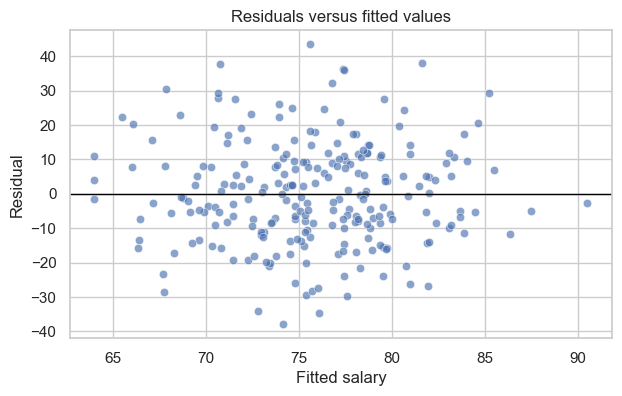

In [14]:
diagnostics = df.assign(fitted=model.fittedvalues, residual=model.resid)
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=diagnostics, x="fitted", y="residual", alpha=0.65, ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Residuals versus fitted values", xlabel="Fitted salary", ylabel="Residual")

## Interpretation

State the slope as an association, with units, and name one omitted variable that could confound it.

β̂ = 0.295 means that if we compare workers who differ in training by one hour, the ones with one more hour earn on average about 0.3 thousand EUR (roughly 295 EUR) more per year in our data. The standard error is 0.06, so the slope is clearly not zero, but the association is weak, R² is 0.092 and only about 9% of the variation in salary is captured by training hours. This is why the 95% prediction interval for a single new worker is so wide, about 60 thousand Euros at every training level. The intercept of 64 thousand Euros is where the line crosses the vertical axis, only three workers have zero training hours so it should not be read too literally, and the prediction at 80 hours is at the edge of the data (only one worker is above 80). The residuals show no curvature and the same spread everywhere, so the linear form is fine. As in class, this is a comparison of averages and not a causal statement. Workers who train more also use AI tools more and earn more, so part of the slope can come from AI tool use, and experience, education and sector are left out of the model too.